# 03— Multi-Dataset Phenotype Pretraining → ICBHI Disease Fine-Tuning

**Goal:** evaluate whether phenotype pretraining on compatible labels from ICBHI, HF Lung V1 and Fraiwan improves ICBHI eight-class disease classification.

This notebook starts with schema and leakage audits. It intentionally does not train until source identifiers and split rules are verified.

## Safeguards
- Never treat phenotype labels as disease labels.
- Keep ICBHI disease validation/test patients out of phenotype pretraining.
- Split by patient/subject, not individual cycles or windows.
- Keep Fraiwan's weak recording-level label granularity visible.
- Use validation for model selection; use test only after choices are frozen.
- Do not overwrite existing manifests, notebooks, or checkpoints.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1
Device: mps


## 2. Project paths

In [2]:
PROJECT_ROOT = Path("/Users/vs/Sem 5/Respiratory-Disease-Classification")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

ICBHI_FEATURE_MANIFEST = PROCESSED_DIR / "features" / "respiratory_cycle_features.csv"
ICBHI_SPLIT_MANIFEST = PROCESSED_DIR / "deep_learning" / "cnn_baseline" / "cnn_patient_disjoint_manifest.csv"
UNIFIED_PHENOTYPE_INDEX = PROCESSED_DIR / "unified_phenotype" / "unified_phenotype_index.csv"

OUTPUT_DIR = PROCESSED_DIR / "deep_learning" / "multidataset_pretraining"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = PROJECT_ROOT / "models" / "multidataset_pretraining"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

for path in [ICBHI_FEATURE_MANIFEST, ICBHI_SPLIT_MANIFEST, UNIFIED_PHENOTYPE_INDEX]:
    print(("FOUND " if path.exists() else "MISSING"), path)

FOUND  /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/features/respiratory_cycle_features.csv
FOUND  /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/cnn_baseline/cnn_patient_disjoint_manifest.csv
FOUND  /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/unified_phenotype/unified_phenotype_index.csv


## 3. Load manifests and inspect schema

In [3]:
icbhi_features = pd.read_csv(ICBHI_FEATURE_MANIFEST) if ICBHI_FEATURE_MANIFEST.exists() else None
icbhi_split = pd.read_csv(ICBHI_SPLIT_MANIFEST) if ICBHI_SPLIT_MANIFEST.exists() else None
unified = pd.read_csv(UNIFIED_PHENOTYPE_INDEX) if UNIFIED_PHENOTYPE_INDEX.exists() else None

for name, frame in [
    ("ICBHI feature manifest", icbhi_features),
    ("ICBHI split manifest", icbhi_split),
    ("Unified phenotype index", unified),
]:
    print(f"\n--- {name} ---")
    if frame is None:
        print("NOT FOUND")
    else:
        print("Shape:", frame.shape)
        print("Columns:", frame.columns.tolist())
        display(frame.head(3))


--- ICBHI feature manifest ---
Shape: (6898, 52)
Columns: ['patient_id', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'cycle_number', 'start_time', 'end_time', 'sound_label', 'crackles', 'wheezes', 'diagnosis', 'processed_path', 'mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy', 'wavelet_entropy', 'wavelet_std']


,patient_id,recording_id,chest_location,acquisition_mode,equipment,cycle_number,start_time,end_time,sound_label,crackles,...,mfcc_7_mean,mfcc_8_mean,mfcc_9_mean,mfcc_10_mean,mfcc_11_mean,mfcc_12_mean,mfcc_13_mean,wavelet_energy,wavelet_entropy,wavelet_std
0,101,1b1,Al,sc,Meditron,1,0.036,0.579,Normal,0,...,14.649715,13.271879,15.322943,4.408390,9.810836,11.595978,6.332477,110.760926,0.062777,0.224449
1,101,1b1,Al,sc,Meditron,2,0.579,2.450,Normal,0,...,11.704497,17.665747,14.362599,8.428231,8.835912,10.312641,6.039036,263.467394,0.090006,0.187299
2,101,1b1,Al,sc,Meditron,3,2.450,3.893,Normal,0,...,9.776377,21.063862,10.441285,5.727220,12.893122,8.313774,3.833181,169.927915,0.150584,0.171195



--- ICBHI split manifest ---
Shape: (6898, 8)
Columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']


,patient_id,recording_id,chest_location,diagnosis,disease_label,official_split,audio_path,cnn_split
0,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test
1,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test
2,101,1b1,Al,URTI,7,test,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,test



--- Unified phenotype index ---
Shape: (55041, 11)
Columns: ['dataset', 'sample_id', 'phenotype_label', 'split', 'source_split', 'subject_id', 'recording_id', 'annotation_granularity', 'label_strength', 'sample_rate', 'audio_path']


,dataset,sample_id,phenotype_label,split,source_split,subject_id,recording_id,annotation_granularity,label_strength,sample_rate,audio_path
0,ICBHI,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,Normal,test,test,101,1b1,respiratory_cycle,event_annotated,4000,audio/cycles/101/1b1_Al_001.wav
1,ICBHI,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,Normal,test,test,101,1b1,respiratory_cycle,event_annotated,4000,audio/cycles/101/1b1_Al_002.wav
2,ICBHI,/Users/vs/Sem 5/Respiratory-Disease-Classifica...,Normal,test,test,101,1b1,respiratory_cycle,event_annotated,4000,audio/cycles/101/1b1_Al_003.wav


## 4. Audit source labels, label strength and support

In [4]:
if unified is None:
    raise FileNotFoundError(f"Unified phenotype index not found: {UNIFIED_PHENOTYPE_INDEX}")

required = {
    "dataset", "sample_id", "phenotype_label", "split", "subject_id",
    "recording_id", "annotation_granularity", "label_strength", "audio_path"
}
missing = required - set(unified.columns)
if missing:
    raise ValueError(f"Unified phenotype index missing columns: {sorted(missing)}")

print("Rows by source:")
display(unified["dataset"].value_counts(dropna=False).rename("rows").to_frame())
print("\nPhenotype counts by source:")
display(pd.crosstab(unified["dataset"], unified["phenotype_label"], margins=True))
print("\nSplit support by source:")
display(pd.crosstab([unified["dataset"], unified["split"]], unified["phenotype_label"]))
print("\nAnnotation granularity:")
display(pd.crosstab(unified["dataset"], unified["annotation_granularity"], margins=True))
print("\nLabel strength:")
display(pd.crosstab(unified["dataset"], unified["label_strength"], margins=True))

Rows by source:


,rows
dataset,
HF Lung V1,47057
ICBHI,6898
Fraiwan,1086



Phenotype counts by source:


phenotype_label,Both,Crackles,Normal,Wheezes,All
dataset,,,,,
Fraiwan,30,294,360,402,1086
HF Lung V1,352,15274,25223,6208,47057
ICBHI,506,1864,3642,886,6898
All,888,17432,29225,7496,55041



Split support by source:


phenotype_label        Both  Crackles  Normal  Wheezes
dataset    split                                      
Fraiwan    test           0        48      60       63
           train         30       210     231      273
           validation     0        36      69       66
HF Lung V1 test          14      1728    5697     1194
           train        338     13546   19526     5014
ICBHI      test         171       462     705      223
           train        316      1219    2342      546
           validation    19       183     595      117


Annotation granularity:


annotation_granularity,five_second_window,respiratory_cycle,respiratory_phase_window,All
dataset,,,,
Fraiwan,1086,0,0,1086
HF Lung V1,0,0,47057,47057
ICBHI,0,6898,0,6898
All,1086,6898,47057,55041



Label strength:


label_strength,event_annotated,recording_level_weak_label,All
dataset,,,
Fraiwan,0,1086,1086
HF Lung V1,47057,0,47057
ICBHI,6898,0,6898
All,53955,1086,55041


## 5. Critical split-isolation design

For the disease transfer experiment:
- Disease fine-tuning train/validation/test use the existing patient-disjoint ICBHI disease manifest.
- Phenotype pretraining can use HF Lung V1 and Fraiwan training partitions, plus only phenotype samples from ICBHI disease-training patients.
- ICBHI disease-validation and disease-test patients must be excluded from pretraining.
- If subject IDs cannot be reliably mapped between manifests, stop and resolve the mapping rather than assuming identifiers match.

In [5]:
print("ICBHI split columns:", [] if icbhi_split is None else icbhi_split.columns.tolist())
print("ICBHI feature columns:", [] if icbhi_features is None else icbhi_features.columns.tolist())

if icbhi_split is None:
    raise FileNotFoundError("ICBHI patient-disjoint manifest is missing.")

for col in ["patient_id", "recording_id", "disease_label", "cnn_split", "official_split"]:
    if col in icbhi_split.columns:
        print(f"\n{col} examples:", icbhi_split[col].dropna().astype(str).unique()[:10])

icbhi_rows = unified[unified["dataset"].astype(str).str.contains("icbhi", case=False, na=False)].copy()
external_rows = unified[~unified.index.isin(icbhi_rows.index)].copy()
print("\nICBHI phenotype rows:", len(icbhi_rows))
print("External phenotype rows:", len(external_rows))
print("External sources:", external_rows["dataset"].value_counts().to_dict())
print("\nICBHI disease split counts:")
split_col = "cnn_split" if "cnn_split" in icbhi_split.columns else ("split" if "split" in icbhi_split.columns else None)
if split_col:
    display(icbhi_split[split_col].value_counts(dropna=False))
else:
    print("No recognized split column; inspect the columns printed above.")

ICBHI split columns: ['patient_id', 'recording_id', 'chest_location', 'diagnosis', 'disease_label', 'official_split', 'audio_path', 'cnn_split']
ICBHI feature columns: ['patient_id', 'recording_id', 'chest_location', 'acquisition_mode', 'equipment', 'cycle_number', 'start_time', 'end_time', 'sound_label', 'crackles', 'wheezes', 'diagnosis', 'processed_path', 'mean', 'std', 'variance', 'rms', 'max', 'min', 'peak_to_peak', 'median', 'skewness', 'kurtosis', 'energy', 'zero_crossing_rate', 'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff', 'spectral_flatness', 'spectral_energy', 'dominant_frequency', 'spectral_entropy', 'band_energy_0_500', 'band_energy_500_1000', 'band_energy_1000_1500', 'band_energy_1500_2000', 'mfcc_1_mean', 'mfcc_2_mean', 'mfcc_3_mean', 'mfcc_4_mean', 'mfcc_5_mean', 'mfcc_6_mean', 'mfcc_7_mean', 'mfcc_8_mean', 'mfcc_9_mean', 'mfcc_10_mean', 'mfcc_11_mean', 'mfcc_12_mean', 'mfcc_13_mean', 'wavelet_energy', 'wavelet_entropy', 'wavelet_std']

patient_id exampl

cnn_split
train         4423
test          1561
validation     914
Name: count, dtype: int64

## 6. Check subject overlap across existing source partitions

In [6]:
for dataset_name, frame in unified.groupby("dataset"):
    print(f"\n### {dataset_name}")
    by_split = {
        str(split): set(group["subject_id"].dropna().astype(str))
        for split, group in frame.groupby("split")
    }
    names = list(by_split)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = names[i], names[j]
            overlap = by_split[a] & by_split[b]
            print(f"{a} vs {b}: subject overlap={len(overlap)}")
            if overlap:
                print("  Example overlaps:", sorted(overlap)[:5])


### Fraiwan
test vs train: subject overlap=0
test vs validation: subject overlap=0
train vs validation: subject overlap=0

### HF Lung V1
test vs train: subject overlap=0

### ICBHI
test vs train: subject overlap=0
test vs validation: subject overlap=0
train vs validation: subject overlap=0


## 7. Stop point — verify identity mapping before constructing training data

Before building a combined pretraining manifest, confirm from the outputs:
1. Which `split` values correspond to train/validation/test for each source.
2. Whether unified ICBHI `subject_id` uses the same identity namespace as `patient_id` in the disease manifest.
3. That HF and Fraiwan IDs are treated as source-specific identities (e.g. `HF:<id>`, `Fraiwan:<id>`) so identical text IDs across datasets do not falsely merge subjects.
4. That the external dataset partitions are subject-disjoint.
5. That no ICBHI validation/test subject enters pretraining.

Do not train until these checks pass.

## 8. Planned experimental matrix

| Run | Phenotype pretraining | Disease fine-tuning | Purpose |
|---|---|---|---|
| Baseline | None | ICBHI disease training split | Disease-only baseline |
| Transfer-HF | HF Lung V1 train partition | Same ICBHI disease train split | Contribution of HF pretraining |
| Transfer-HF+Fraiwan | HF + Fraiwan train partitions | Same ICBHI disease train split | Contribution of additional weakly labelled source |

Keep the ICBHI validation/test cohort identical across runs. Report macro-F1, balanced accuracy, per-class recall and confusion matrices; repeat seeds if feasible.

## 9. Next steps after the audit
1. Run Sections 1–6 and inspect all outputs.
2. Resolve source-specific subject IDs and split semantics.
3. Build and save an explicit audited pretraining manifest.
4. Add compact phenotype pretraining and disease fine-tuning loops.
5. Compare all transfer runs against the ICBHI-only baseline on the same held-out test cohort.

In [7]:

# Section 7 — Build and validate the leakage-safe pretraining manifest

import os
from pathlib import Path

# 1. Select only the existing training partitions.
pretrain_manifest = unified[
    unified["split"].astype(str).str.lower().eq("train")
].copy()

# Keep ICBHI and external sources explicit.
expected_sources = {"ICBHI", "HF Lung V1", "Fraiwan"}
found_sources = set(pretrain_manifest["dataset"].astype(str))
assert expected_sources.issubset(found_sources), (
    f"Missing training sources: {expected_sources - found_sources}"
)

# 2. Confirm ICBHI phenotype training patients match disease-training patients.
icbhi_pretrain = pretrain_manifest[
    pretrain_manifest["dataset"].astype(str).eq("ICBHI")
]
disease_train_patients = set(
    icbhi_split.loc[
        icbhi_split["cnn_split"].astype(str).eq("train"),
        "patient_id"
    ].astype(str)
)
phenotype_train_patients = set(icbhi_pretrain["subject_id"].astype(str))

print("ICBHI disease-training patients:", len(disease_train_patients))
print("ICBHI phenotype-training patients:", len(phenotype_train_patients))
print("ICBHI patient sets match:", disease_train_patients == phenotype_train_patients)

assert disease_train_patients == phenotype_train_patients, (
    "ICBHI phenotype and disease training patients do not match. "
    "Stop and inspect the identity mapping."
)

# 3. Namespace subjects by dataset to prevent cross-dataset ID collisions.
pretrain_manifest["source_subject_id"] = (
    pretrain_manifest["dataset"].astype(str)
    + ":"
    + pretrain_manifest["subject_id"].astype(str)
)

# 4. Resolve audio paths without changing the source index.
def resolve_audio_path(value):
    p = Path(str(value)).expanduser()
    if p.is_absolute():
        return p

    candidates = [
        PROJECT_ROOT / p,
        PROCESSED_DIR / p,
        PROCESSED_DIR / "deep_learning" / "cnn_baseline" / p,
        PROCESSED_DIR / "unified_phenotype" / p,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    return candidates[0]  # retain expected location for diagnostics

pretrain_manifest["resolved_audio_path"] = (
    pretrain_manifest["audio_path"].map(resolve_audio_path).astype(str)
)

# 5. Report source, phenotype and path support.
print("\nPretraining samples by source:")
display(pretrain_manifest.groupby("dataset").size().rename("samples").to_frame())

print("\nPretraining phenotype counts:")
display(pd.crosstab(
    pretrain_manifest["dataset"],
    pretrain_manifest["phenotype_label"],
    margins=True
))

missing_paths = pretrain_manifest[
    ~pretrain_manifest["resolved_audio_path"].map(lambda p: Path(p).is_file())
]
print("\nTotal pretraining rows:", len(pretrain_manifest))
print("Missing audio paths:", len(missing_paths))

if len(missing_paths):
    display(missing_paths[
        ["dataset", "sample_id", "audio_path", "resolved_audio_path"]
    ].head(10))
else:
    print("All pretraining audio paths exist.")

# 6. Save an audit artifact only if all paths are valid.
if len(missing_paths) == 0:
    output_path = OUTPUT_DIR / "phenotype_pretraining_manifest.csv"
    pretrain_manifest.to_csv(output_path, index=False)
    print("\nSaved manifest:", output_path)
else:
    print("\nManifest NOT saved: resolve missing paths before proceeding.")


ICBHI disease-training patients: 82
ICBHI phenotype-training patients: 82
ICBHI patient sets match: True

Pretraining samples by source:


,samples
dataset,
Fraiwan,744
HF Lung V1,38424
ICBHI,4423



Pretraining phenotype counts:


phenotype_label,Both,Crackles,Normal,Wheezes,All
dataset,,,,,
Fraiwan,30,210,231,273,744
HF Lung V1,338,13546,19526,5014,38424
ICBHI,316,1219,2342,546,4423
All,684,14975,22099,5833,43591



Total pretraining rows: 43591
Missing audio paths: 0
All pretraining audio paths exist.

Saved manifest: /Users/vs/Sem 5/Respiratory-Disease-Classification/data/processed/deep_learning/multidataset_pretraining/phenotype_pretraining_manifest.csv


In [8]:

# Section 8 — Final ICBHI patient-isolation check

saved_manifest_path = (
    OUTPUT_DIR / "phenotype_pretraining_manifest.csv"
)

pretrain_check = pd.read_csv(saved_manifest_path)

# Identify ICBHI rows in the pretraining manifest.
icbhi_pretrain_check = pretrain_check[
    pretrain_check["dataset"].astype(str).eq("ICBHI")
]

# Disease split patient sets.
train_patients = set(
    icbhi_split.loc[
        icbhi_split["cnn_split"].astype(str).eq("train"),
        "patient_id"
    ].astype(str)
)
val_patients = set(
    icbhi_split.loc[
        icbhi_split["cnn_split"].astype(str).eq("validation"),
        "patient_id"
    ].astype(str)
)
test_patients = set(
    icbhi_split.loc[
        icbhi_split["cnn_split"].astype(str).eq("test"),
        "patient_id"
    ].astype(str)
)

# Compare identifiers only within ICBHI.
pretrain_patients = set(
    icbhi_pretrain_check["subject_id"].astype(str)
)

print("ICBHI pretraining patients:", len(pretrain_patients))
print("Expected ICBHI training patients:", len(train_patients))
print("Overlap with disease training:", len(pretrain_patients & train_patients))
print("Overlap with disease validation:", len(pretrain_patients & val_patients))
print("Overlap with disease test:", len(pretrain_patients & test_patients))

assert pretrain_patients == train_patients
assert pretrain_patients.isdisjoint(val_patients)
assert pretrain_patients.isdisjoint(test_patients)

print("\nICBHI patient-isolation checks PASSED.")


ICBHI pretraining patients: 82
Expected ICBHI training patients: 82
Overlap with disease training: 82
Overlap with disease validation: 0
Overlap with disease test: 0

ICBHI patient-isolation checks PASSED.


In [9]:

# Section 9 — Verify external source partitions

external = pretrain_check[
    pretrain_check["dataset"].astype(str).isin(["HF Lung V1", "Fraiwan"])
].copy()

print("External samples by source and split:")
display(pd.crosstab(
    external["dataset"],
    external["split"],
    margins=True
))

# Only the designated training partition is eligible for pretraining.
external_train = external[
    external["split"].astype(str).str.lower().eq("train")
].copy()

assert set(external_train["dataset"].astype(str)) == {
    "HF Lung V1", "Fraiwan"
}

assert external_train["phenotype_label"].isin(
    ["Normal", "Crackles", "Wheezes", "Both"]
).all()

# Keep source-specific subject identities.
external_train["source_subject_id"] = (
    external_train["dataset"].astype(str)
    + ":"
    + external_train["subject_id"].astype(str)
)

print("\nEligible external pretraining samples:")
display(external_train.groupby("dataset").agg(
    samples=("sample_id", "size"),
    subjects=("source_subject_id", "nunique"),
    recordings=("recording_id", "nunique")
))

print("\nPhenotype distribution:")
display(pd.crosstab(
    external_train["dataset"],
    external_train["phenotype_label"],
    margins=True
))

# Verify that every eligible path exists.
missing = external_train[
    ~external_train["resolved_audio_path"].map(
        lambda p: Path(p).is_file()
    )
]

print("\nMissing audio paths:", len(missing))
assert len(missing) == 0, "Resolve missing audio paths before training."

# Save an explicit external-only training manifest.
hf_train = external_train[
    external_train["dataset"].eq("HF Lung V1")
].copy()

hf_fraiwan_train = external_train.copy()

hf_train.to_csv(OUTPUT_DIR / "hf_phenotype_train_manifest.csv", index=False)
hf_fraiwan_train.to_csv(
    OUTPUT_DIR / "hf_fraiwan_phenotype_train_manifest.csv",
    index=False
)

print("\nSaved HF-only and HF+Fraiwan training manifests.")


External samples by source and split:


split,train,All
dataset,,
Fraiwan,744,744
HF Lung V1,38424,38424
All,39168,39168



Eligible external pretraining samples:


,samples,subjects,recordings
dataset,,,
Fraiwan,744,72,216
HF Lung V1,38424,115,7278



Phenotype distribution:


phenotype_label,Both,Crackles,Normal,Wheezes,All
dataset,,,,,
Fraiwan,30,210,231,273,744
HF Lung V1,338,13546,19526,5014,38424
All,368,13756,19757,5287,39168



Missing audio paths: 0

Saved HF-only and HF+Fraiwan training manifests.


In [10]:

# Section 10 — Phenotype dataset and compact encoder

import soundfile as sf
import librosa
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

PHENOTYPE_CLASSES = ["Normal", "Crackles", "Wheezes", "Both"]
PHENOTYPE_TO_ID = {
    name: idx for idx, name in enumerate(PHENOTYPE_CLASSES)
}

TARGET_SR = 4000
TARGET_SECONDS = 3.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_SECONDS)

BATCH_SIZE = 64
NUM_WORKERS = 0  # reliable default for macOS/Jupyter


def load_waveform(path):
    """Load mono audio and standardize it to 4 kHz and 3 seconds."""
    waveform, sr = sf.read(str(path))

    if waveform.ndim > 1:
        waveform = waveform.mean(axis=1)

    waveform = waveform.astype(np.float32)

    if sr != TARGET_SR:
        waveform = librosa.resample(
            waveform,
            orig_sr=sr,
            target_sr=TARGET_SR
        ).astype(np.float32)

    # Center crop long recordings; zero-pad short recordings.
    if len(waveform) > TARGET_SAMPLES:
        start = (len(waveform) - TARGET_SAMPLES) // 2
        waveform = waveform[start:start + TARGET_SAMPLES]
    elif len(waveform) < TARGET_SAMPLES:
        missing = TARGET_SAMPLES - len(waveform)
        left = missing // 2
        right = missing - left
        waveform = np.pad(waveform, (left, right))

    return waveform.astype(np.float32)


class PhenotypeAudioDataset(Dataset):
    def __init__(self, manifest):
        self.manifest = manifest.reset_index(drop=True).copy()

        unknown = set(self.manifest["phenotype_label"].dropna()) - set(
            PHENOTYPE_CLASSES
        )
        if unknown:
            raise ValueError(f"Unexpected phenotype labels: {unknown}")

        if self.manifest["phenotype_label"].isna().any():
            raise ValueError("Missing phenotype labels found.")

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, index):
        row = self.manifest.iloc[index]
        waveform = load_waveform(row["resolved_audio_path"])
        label = PHENOTYPE_TO_ID[row["phenotype_label"]]

        return (
            torch.from_numpy(waveform).unsqueeze(0),
            torch.tensor(label, dtype=torch.long)
        )


class CompactRespiratoryEncoder(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=9, stride=2, padding=4,
                      bias=False),
            nn.BatchNorm1d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(4),

            nn.Conv1d(16, 32, kernel_size=7, stride=1, padding=3,
                      bias=False),
            nn.BatchNorm1d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool1d(4),

            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2,
                      bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),

            nn.Conv1d(64, 64, kernel_size=3, stride=1, padding=1,
                      bias=False),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool1d(1),
            nn.Flatten()
        )

        self.classifier = nn.Linear(64, num_classes)

    def forward(self, waveform):
        embedding = self.features(waveform)
        return self.classifier(embedding)


# Build datasets from the manifests already audited.
hf_dataset = PhenotypeAudioDataset(hf_train)
hf_fraiwan_dataset = PhenotypeAudioDataset(hf_fraiwan_train)

hf_loader = DataLoader(
    hf_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

hf_fraiwan_loader = DataLoader(
    hf_fraiwan_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

model_check = CompactRespiratoryEncoder().to(DEVICE)
parameter_count = sum(
    p.numel() for p in model_check.parameters() if p.requires_grad
)

waveform_batch, label_batch = next(iter(hf_loader))
with torch.no_grad():
    output_batch = model_check(waveform_batch.to(DEVICE))

print("Phenotype classes:", PHENOTYPE_TO_ID)
print("HF dataset size:", len(hf_dataset))
print("HF + Fraiwan dataset size:", len(hf_fraiwan_dataset))
print("Waveform batch shape:", tuple(waveform_batch.shape))
print("Label batch shape:", tuple(label_batch.shape))
print("Output shape:", tuple(output_batch.shape))
print(f"Trainable parameters: {parameter_count:,}")

assert waveform_batch.shape[1:] == (1, TARGET_SAMPLES)
assert output_batch.shape[1] == len(PHENOTYPE_CLASSES)

print("Model and data-loader checks passed.")


Phenotype classes: {'Normal': 0, 'Crackles': 1, 'Wheezes': 2, 'Both': 3}
HF dataset size: 38424
HF + Fraiwan dataset size: 39168
Waveform batch shape: (64, 1, 12000)
Label batch shape: (64,)
Output shape: (64, 4)
Trainable parameters: 26,868
Model and data-loader checks passed.


In [11]:

# Section 11 — Inspect source-specific phenotype validation partitions

full_index = pd.read_csv(UNIFIED_PHENOTYPE_INDEX)

print("All source split counts:")
display(pd.crosstab(
    full_index["dataset"],
    full_index["split"],
    margins=True
))

print("\nPhenotype support by source and split:")
display(pd.crosstab(
    [full_index["dataset"], full_index["split"]],
    full_index["phenotype_label"],
    margins=True
))

print("\nUnique subjects by source and split:")
subject_support = (
    full_index.groupby(["dataset", "split"])
    .agg(
        samples=("sample_id", "size"),
        subjects=("subject_id", "nunique"),
        recordings=("recording_id", "nunique")
    )
    .reset_index()
)
display(subject_support)

print("\nImportant:")
print("- HF Lung V1 may use its official test partition for phenotype validation.")
print("- Fraiwan has its own subject-grouped train/validation/test partitions.")
print("- ICBHI phenotype validation/test patients must remain excluded from pretraining.")
print("- Do not use any external validation/test samples for gradient updates.")


All source split counts:


split,test,train,validation,All
dataset,,,,
Fraiwan,171,744,171,1086
HF Lung V1,8633,38424,0,47057
ICBHI,1561,4423,914,6898
All,10365,43591,1085,55041



Phenotype support by source and split:


phenotype_label        Both  Crackles  Normal  Wheezes    All
dataset    split                                             
Fraiwan    test           0        48      60       63    171
           train         30       210     231      273    744
           validation     0        36      69       66    171
HF Lung V1 test          14      1728    5697     1194   8633
           train        338     13546   19526     5014  38424
ICBHI      test         171       462     705      223   1561
           train        316      1219    2342      546   4423
           validation    19       183     595      117    914
All                     888     17432   29225     7496  55041


Unique subjects by source and split:


,dataset,split,samples,subjects,recordings
0,Fraiwan,test,171,16,47
1,Fraiwan,train,744,72,216
2,Fraiwan,validation,171,16,48
3,HF Lung V1,test,8633,39,1850
4,HF Lung V1,train,38424,115,7278
5,ICBHI,test,1561,25,19
6,ICBHI,train,4423,82,32
7,ICBHI,validation,914,19,18



Important:
- HF Lung V1 may use its official test partition for phenotype validation.
- Fraiwan has its own subject-grouped train/validation/test partitions.
- ICBHI phenotype validation/test patients must remain excluded from pretraining.
- Do not use any external validation/test samples for gradient updates.


In [12]:

# Section 12 — Create HF-only phenotype train/validation split

from sklearn.model_selection import GroupShuffleSplit

full_index = pd.read_csv(UNIFIED_PHENOTYPE_INDEX)

hf_train_all = full_index[
    full_index["dataset"].eq("HF Lung V1")
    & full_index["split"].astype(str).str.lower().eq("train")
].copy()

# Split by subject, never by individual window.
assert hf_train_all["subject_id"].notna().all()
assert hf_train_all["phenotype_label"].notna().all()

# Try a few deterministic group splits until both partitions contain all classes.
selected = None

for seed in [42, 7, 21, 123, 2026, 314]:
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=seed
    )

    train_idx, val_idx = next(
        splitter.split(
            hf_train_all,
            groups=hf_train_all["subject_id"].astype(str)
        )
    )

    candidate_train = hf_train_all.iloc[train_idx].copy()
    candidate_val = hf_train_all.iloc[val_idx].copy()

    expected = {"Normal", "Crackles", "Wheezes", "Both"}
    train_classes = set(candidate_train["phenotype_label"].unique())
    val_classes = set(candidate_val["phenotype_label"].unique())

    if train_classes == expected and val_classes == expected:
        selected = (seed, candidate_train, candidate_val)
        break

if selected is None:
    raise RuntimeError(
        "Could not find a group split with all four classes in both partitions. "
        "Inspect per-subject class support; do not fall back to a random window split."
    )

split_seed, hf_pretrain_train, hf_pretrain_val = selected

train_subjects = set(hf_pretrain_train["subject_id"].astype(str))
val_subjects = set(hf_pretrain_val["subject_id"].astype(str))
official_test_subjects = set(
    full_index.loc[
        full_index["dataset"].eq("HF Lung V1")
        & full_index["split"].astype(str).str.lower().eq("test"),
        "subject_id"
    ].astype(str)
)

assert train_subjects.isdisjoint(val_subjects)
assert train_subjects.isdisjoint(official_test_subjects)
assert val_subjects.isdisjoint(official_test_subjects)

print("Selected random seed:", split_seed)
print("Train rows / subjects:", len(hf_pretrain_train), hf_pretrain_train["subject_id"].nunique())
print("Validation rows / subjects:", len(hf_pretrain_val), hf_pretrain_val["subject_id"].nunique())
print("Overlap train-validation:", len(train_subjects & val_subjects))
print("Overlap with official HF test:",
      len((train_subjects | val_subjects) & official_test_subjects))

print("\nTraining phenotype counts:")
display(hf_pretrain_train["phenotype_label"].value_counts().reindex(
    ["Normal", "Crackles", "Wheezes", "Both"], fill_value=0
).rename("train_samples").to_frame())

print("\nValidation phenotype counts:")
display(hf_pretrain_val["phenotype_label"].value_counts().reindex(
    ["Normal", "Crackles", "Wheezes", "Both"], fill_value=0
).rename("validation_samples").to_frame())

# Keep original paths and save a separate experiment manifest.
for frame in [hf_pretrain_train, hf_pretrain_val]:
    frame["resolved_audio_path"] = frame["audio_path"].map(resolve_audio_path).astype(str)

assert hf_pretrain_train["resolved_audio_path"].map(lambda p: Path(p).is_file()).all()
assert hf_pretrain_val["resolved_audio_path"].map(lambda p: Path(p).is_file()).all()

hf_pretrain_train.to_csv(
    OUTPUT_DIR / "hf_phenotype_pretrain_train.csv", index=False
)
hf_pretrain_val.to_csv(
    OUTPUT_DIR / "hf_phenotype_pretrain_validation.csv", index=False
)

print("\nSaved HF phenotype training and validation manifests.")


Selected random seed: 42
Train rows / subjects: 25883 97
Validation rows / subjects: 12541 18
Overlap train-validation: 0
Overlap with official HF test: 0

Training phenotype counts:


,train_samples
phenotype_label,
Normal,13413
Crackles,8457
Wheezes,3807
Both,206



Validation phenotype counts:


,validation_samples
phenotype_label,
Normal,6113
Crackles,5089
Wheezes,1207
Both,132



Saved HF phenotype training and validation manifests.


In [13]:

# Section 13 — Train HF Lung V1 phenotype model

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score
import copy
import time

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BATCH_SIZE = 64
MAX_EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

hf_train_ds = PhenotypeAudioDataset(hf_pretrain_train)
hf_val_ds = PhenotypeAudioDataset(hf_pretrain_val)

hf_train_loader = DataLoader(
    hf_train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)
hf_val_loader = DataLoader(
    hf_val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

# Class weights are calculated from training labels only.
y_train = hf_pretrain_train["phenotype_label"].map(
    PHENOTYPE_TO_ID
).to_numpy()

class_ids = np.arange(len(PHENOTYPE_CLASSES))
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=y_train
)
class_weights = torch.tensor(
    weights, dtype=torch.float32, device=DEVICE
)

print("Phenotype class weights:")
print(dict(zip(PHENOTYPE_CLASSES, weights.round(3))))

model_hf = CompactRespiratoryEncoder(
    num_classes=len(PHENOTYPE_CLASSES)
).to(DEVICE)

criterion_hf = nn.CrossEntropyLoss(weight=class_weights)
optimizer_hf = torch.optim.AdamW(
    model_hf.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
scheduler_hf = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_hf, mode="max", factor=0.5, patience=2
)

def phenotype_epoch(model, loader, optimizer=None, criterion=None):
    training = optimizer is not None
    model.train(training)

    all_labels, all_preds, losses = [], [], []

    for waveforms, labels in loader:
        waveforms = waveforms.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(waveforms)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=5.0
                )
                optimizer.step()

        losses.append(loss.detach().item())
        all_labels.extend(labels.detach().cpu().numpy())
        all_preds.extend(logits.argmax(1).detach().cpu().numpy())

    return {
        "loss": float(np.mean(losses)),
        "accuracy": accuracy_score(all_labels, all_preds),
        "macro_f1": f1_score(
            all_labels, all_preds,
            labels=list(range(len(PHENOTYPE_CLASSES))),
            average="macro", zero_division=0
        ),
        "y_true": np.asarray(all_labels),
        "y_pred": np.asarray(all_preds)
    }

best_f1 = -1.0
best_epoch = 0
best_state = None
wait = 0
history_hf = []

checkpoint_hf = MODEL_DIR / "phenotype_encoder_hf_best.pt"

for epoch in range(1, MAX_EPOCHS + 1):
    start_time = time.time()

    train_result = phenotype_epoch(
        model_hf, hf_train_loader,
        optimizer=optimizer_hf, criterion=criterion_hf
    )
    val_result = phenotype_epoch(
        model_hf, hf_val_loader,
        criterion=criterion_hf
    )

    scheduler_hf.step(val_result["macro_f1"])

    history_hf.append({
        "epoch": epoch,
        "train_loss": train_result["loss"],
        "train_accuracy": train_result["accuracy"],
        "train_macro_f1": train_result["macro_f1"],
        "val_loss": val_result["loss"],
        "val_accuracy": val_result["accuracy"],
        "val_macro_f1": val_result["macro_f1"],
        "seconds": time.time() - start_time
    })

    print(
        f"Epoch {epoch:02d} | "
        f"train loss={train_result['loss']:.4f}, "
        f"train macro-F1={train_result['macro_f1']:.4f} | "
        f"val loss={val_result['loss']:.4f}, "
        f"val macro-F1={val_result['macro_f1']:.4f} | "
        f"{history_hf[-1]['seconds']:.1f}s"
    )

    if val_result["macro_f1"] > best_f1:
        best_f1 = val_result["macro_f1"]
        best_epoch = epoch
        best_state = copy.deepcopy(model_hf.state_dict())
        wait = 0

        torch.save({
            "model_state_dict": best_state,
            "phenotype_classes": PHENOTYPE_CLASSES,
            "target_sr": TARGET_SR,
            "target_seconds": TARGET_SECONDS,
            "num_parameters": sum(
                p.numel() for p in model_hf.parameters()
                if p.requires_grad
            ),
            "best_epoch": best_epoch,
            "best_val_macro_f1": best_f1,
            "seed": SEED
        }, checkpoint_hf)
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping.")
        break

history_hf_df = pd.DataFrame(history_hf)
history_hf_df.to_csv(
    OUTPUT_DIR / "hf_phenotype_training_history.csv",
    index=False
)

print("\nBest epoch:", best_epoch)
print("Best validation macro-F1:", round(best_f1, 4))
print("Saved checkpoint:", checkpoint_hf)


Phenotype class weights:
{'Normal': np.float64(0.482), 'Crackles': np.float64(0.765), 'Wheezes': np.float64(1.7), 'Both': np.float64(31.411)}
Epoch 01 | train loss=1.2492, train macro-F1=0.3913 | val loss=1.2266, val macro-F1=0.3813 | 26.1s
Epoch 02 | train loss=1.1817, train macro-F1=0.4263 | val loss=1.2581, val macro-F1=0.3754 | 21.6s
Epoch 03 | train loss=1.1548, train macro-F1=0.4414 | val loss=1.2491, val macro-F1=0.3992 | 21.3s
Epoch 04 | train loss=1.1441, train macro-F1=0.4510 | val loss=1.2431, val macro-F1=0.4009 | 21.4s
Epoch 05 | train loss=1.1313, train macro-F1=0.4472 | val loss=1.2986, val macro-F1=0.3779 | 21.5s
Epoch 06 | train loss=1.1253, train macro-F1=0.4515 | val loss=1.2115, val macro-F1=0.3882 | 21.3s
Epoch 07 | train loss=1.1089, train macro-F1=0.4623 | val loss=1.2375, val macro-F1=0.3992 | 21.2s
Epoch 08 | train loss=1.0788, train macro-F1=0.4706 | val loss=1.2225, val macro-F1=0.4076 | 21.3s
Epoch 09 | train loss=1.0675, train macro-F1=0.4772 | val loss=1.2

Best epoch: 8
Saved validation macro-F1: 0.407610602180537
Re-evaluated validation macro-F1: 0.407610602180537
Validation accuracy: 0.5079339765568934

Per-class report:
              precision    recall  f1-score   support

      Normal       0.60      0.42      0.49      6113
    Crackles       0.49      0.62      0.55      5089
     Wheezes       0.43      0.53      0.48      1207
        Both       0.08      0.20      0.12       132

    accuracy                           0.51     12541
   macro avg       0.40      0.44      0.41     12541
weighted avg       0.53      0.51      0.51     12541



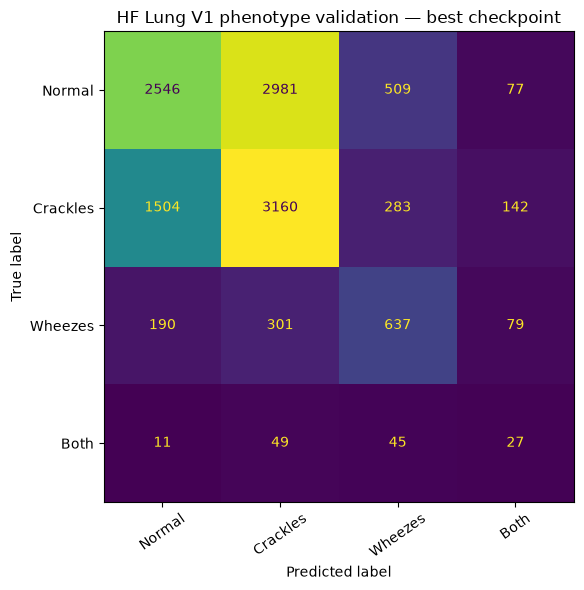

In [15]:

# Section 14 — Per-class validation evaluation of the best HF checkpoint

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
import torch

checkpoint = torch.load(
    MODEL_DIR / "phenotype_encoder_hf_best.pt",
    map_location=DEVICE,
    weights_only=False
)

best_hf_model = CompactRespiratoryEncoder(
    num_classes=len(PHENOTYPE_CLASSES)
).to(DEVICE)

best_hf_model.load_state_dict(checkpoint["model_state_dict"])
best_hf_model.eval()

val_result = phenotype_epoch(
    best_hf_model,
    hf_val_loader,
    criterion=nn.CrossEntropyLoss(weight=class_weights)
)

print("Best epoch:", checkpoint["best_epoch"])
print("Saved validation macro-F1:", checkpoint["best_val_macro_f1"])
print("Re-evaluated validation macro-F1:", val_result["macro_f1"])
print("Validation accuracy:", val_result["accuracy"])

print("\nPer-class report:")
print(classification_report(
    val_result["y_true"],
    val_result["y_pred"],
    labels=list(range(len(PHENOTYPE_CLASSES))),
    target_names=PHENOTYPE_CLASSES,
    zero_division=0
))

cm = confusion_matrix(
    val_result["y_true"],
    val_result["y_pred"],
    labels=list(range(len(PHENOTYPE_CLASSES)))
)
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=PHENOTYPE_CLASSES
)
disp.plot(ax=ax, xticks_rotation=35, colorbar=False)
ax.set_title("HF Lung V1 phenotype validation — best checkpoint")
plt.tight_layout()
plt.show()
